 Proyek Tugas Besar Mata Kuliah Data Mining

Kelompok :
<br>Raka Zeniusa Barron (220102070)
<br>Shofa Farhah Tanzilah (220102080)
<br>Arina Sabilana (220102016)

# Rumusan Masalah

1. Bagaimana memprediksi tingkat stres mahasiswa selama pembelajaran daring menggunakan data aktivitas harian mereka?
2. Fitur apa saja yang paling berpengaruh terhadap tingkat stres?
3. Apakah pola hidup mahasiswa dapat dikelompokkan ke dalam tipe-tipe tertentu tanpa melihat tingkat stres secara langsung?
4. Seberapa akurat model dalam mengklasifikasikan tingkat stres mahasiswa baru berdasarkan data sederhana?

# Model

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_selection import mutual_info_classif
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from collections import Counter

## Import Dataset

In [2]:

df = pd.read_csv("dataset/Student Mental Health Analysis.csv")

Kolom-kolom pada dataset:
<br>Name – Nama responden.
<br>Gender – Jenis kelamin.
<br>Age – Usia.
<br>Screen Time (hrs/day) – Waktu di depan layar per hari.
<br>Sleep Duration (hrs) – Durasi tidur harian.
<br>Physical Activity (hrs/week) – Aktivitas fisik per minggu.
<br>Stress Level – Tingkat stres (Low, Medium, High).


## Preprocessing Data

Pembersihan Data

**Menghapus Kolom Tidak Relevan**
<br>Pada dataset ini terdapat kolom Name hanya berisi identitas dan tidak relevan untuk analisis. Kita akan drop kolom ini.

In [3]:
# Menghapus kolom tidak relevan
df.drop(columns=['Name'], inplace=True)

Memeriksa Missing Values

In [4]:
# Cek missing value dan tipe data
print(df.isnull().sum())
print(df.dtypes)

Gender                          0
Age                             0
Screen Time (hrs/day)           0
Sleep Duration (hrs)            0
Physical Activity (hrs/week)    0
Stress Level                    0
dtype: int64
Gender                           object
Age                               int64
Screen Time (hrs/day)           float64
Sleep Duration (hrs)            float64
Physical Activity (hrs/week)    float64
Stress Level                     object
dtype: object


**Menstandarisasi Format String**



In [5]:
df['Gender'] = df['Gender'].str.strip().str.capitalize()
df['Stress Level'] = df['Stress Level'].str.strip().str.capitalize()

Melakukan stadarisasi untuk data data dalam kolom kategorikal
<br>.str.strip() → hapus spasi di awal/akhir.
<br>.str.capitalize() → huruf pertama besar, lainnya kecil (contoh: male → Male).

**Encoding dan Normalisasi Data**
<br>Melakukan Label Encoding untuk target/label input
<br> menggunakan StandardScaler dari sklearn: skala semua fitur numerik ke mean = 0, standar deviasi = 1.

In [6]:
le_gender = LabelEncoder()
df['Gender'] = le_gender.fit_transform(df['Gender'])
print("Gender Classes:", le_gender.classes_)


le_stress = LabelEncoder()
df['Stress Level'] = le_stress.fit_transform(df['Stress Level'])
print("Stress Level Classes:", le_stress.classes_)


Gender Classes: ['Female' 'Male' 'Other']
Stress Level Classes: ['High' 'Low' 'Medium']


Outlier Removal

In [7]:
df_clean = df.copy()
features_to_check = ['Sleep Duration (hrs)', 'Screen Time (hrs/day)', 'Physical Activity (hrs/week)']

for col in features_to_check:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

print("Jumlah data awal:", len(df))
print("Jumlah data setelah outlier removal:", len(df_clean))
df = df_clean.reset_index(drop=True)

Jumlah data awal: 1000
Jumlah data setelah outlier removal: 1000


Feature Engineering

In [8]:
df['Screen Time (log)'] = np.log1p(df['Screen Time (hrs/day)'])
df['Physical Activity (sqrt)'] = np.sqrt(df['Physical Activity (hrs/week)'])

Segmentasi Berdasarkan Umur

In [9]:
df_young = df[df['Age'] <= 18]
df_adult = df[df['Age'] > 18]

EDA: VISUALISASI

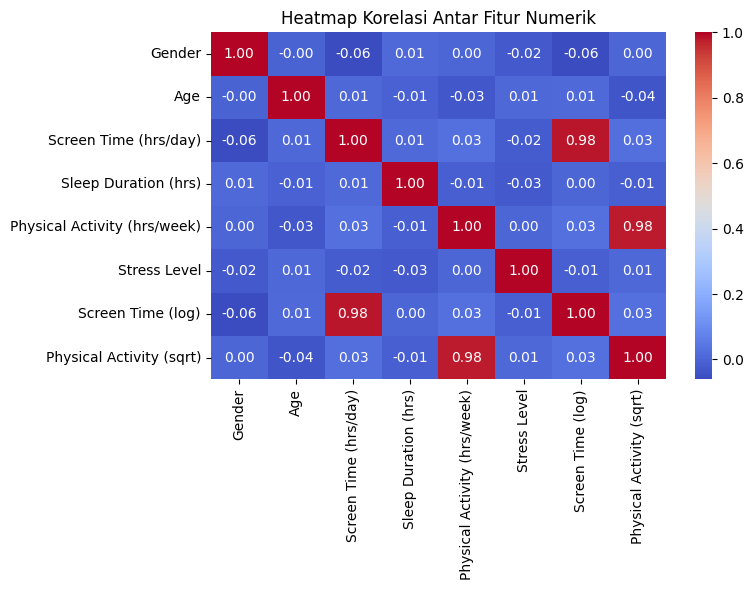

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Heatmap Korelasi Antar Fitur Numerik")
plt.tight_layout()
plt.show()


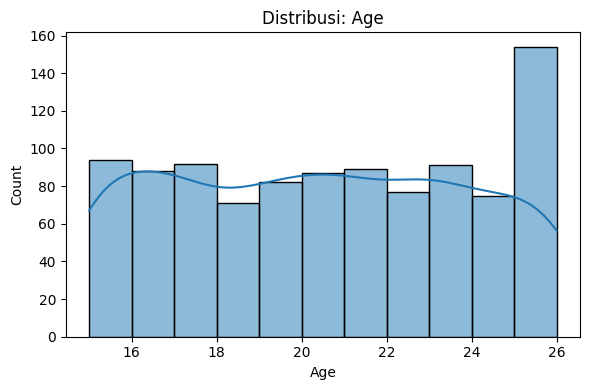

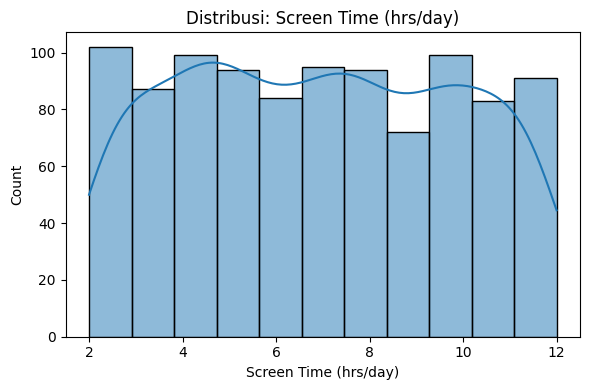

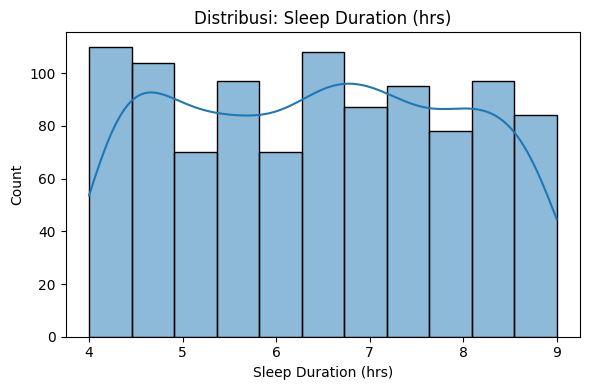

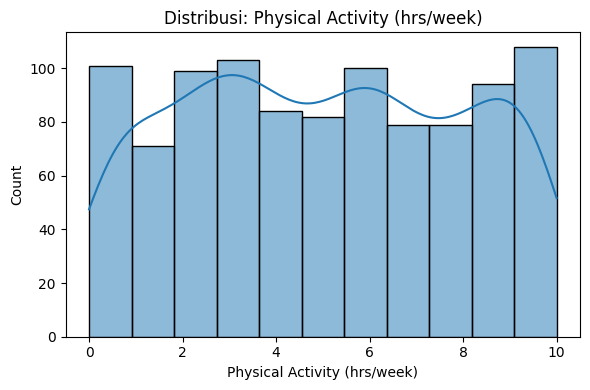

In [11]:
features_to_plot = ['Age', 'Screen Time (hrs/day)', 'Sleep Duration (hrs)', 'Physical Activity (hrs/week)']
for col in features_to_plot:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribusi: {col}")
    plt.tight_layout()
    plt.show()

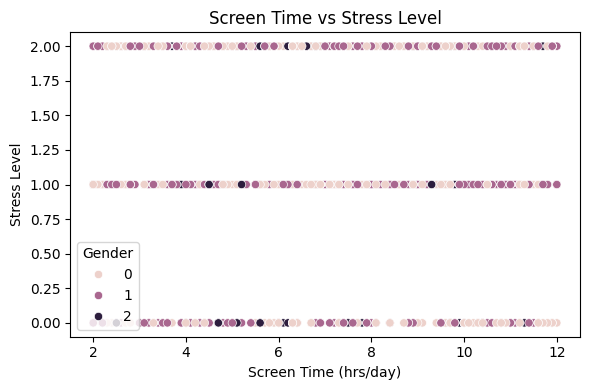

In [12]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='Screen Time (hrs/day)', y='Stress Level', hue='Gender')
plt.title("Screen Time vs Stress Level")
plt.tight_layout()
plt.show()

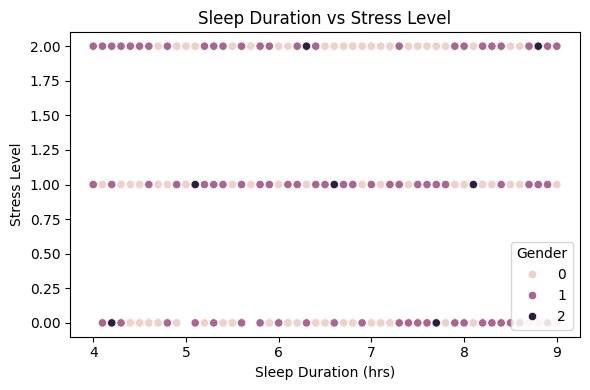

In [13]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='Sleep Duration (hrs)', y='Stress Level', hue='Gender')
plt.title("Sleep Duration vs Stress Level")
plt.tight_layout()
plt.show()

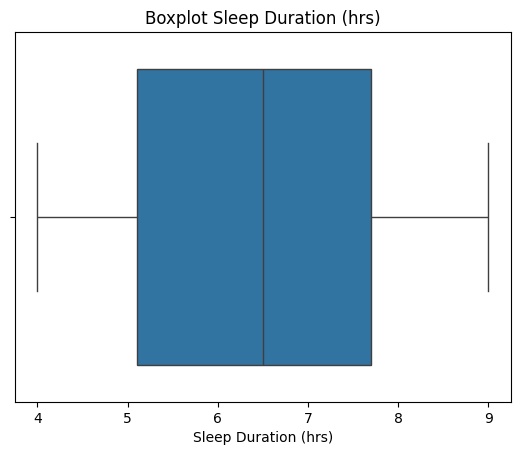

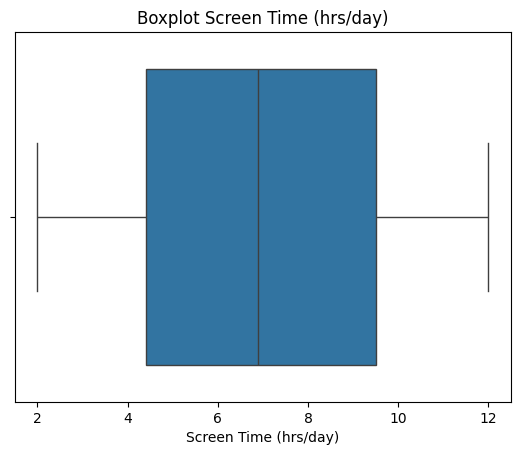

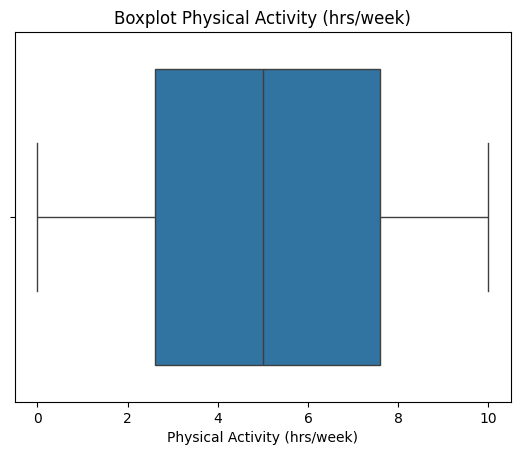

In [14]:
for col in features_to_check:
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot {col}")
    plt.show()

Mutual Sistem Analysis

In [15]:
X = df.drop("Stress Level", axis=1)
y = df["Stress Level"]

importances = mutual_info_classif(X, y, discrete_features="auto")
print("Mutual Information Scores:")
for col, score in zip(X.columns, importances):
    print(f"{col}: {score:.4f}")

Mutual Information Scores:
Gender: 0.0000
Age: 0.0000
Screen Time (hrs/day): 0.0045
Sleep Duration (hrs): 0.0088
Physical Activity (hrs/week): 0.0117
Screen Time (log): 0.0000
Physical Activity (sqrt): 0.0000


SCALING + SMOTE + SPLIT

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Distribusi sebelum SMOTE:", Counter(y))
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)
print("Distribusi setelah SMOTE:", Counter(y_resampled))

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled
)


Distribusi sebelum SMOTE: Counter({2: 492, 1: 327, 0: 181})
Distribusi setelah SMOTE: Counter({2: 492, 0: 492, 1: 492})


## Modeling

### Supervised Learning

Training & Evaluasi Model Klasifikasi
<br>Model: RandomForestClassifier
  <br>Evaluasi: accuracy_score, classification_report, confusion_matrix

In [17]:
# 1. Inisialisasi dan Training Model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [18]:
# 2. Prediksi Data Uji
y_pred = model.predict(X_test)

In [19]:
# 3. Evaluasi Akurasi
acc = accuracy_score(y_test, y_pred)
print(f"Akurasi: {acc:.4f}")

Akurasi: 0.6115


In [20]:
# 4. Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le_stress.classes_))

Classification Report:
              precision    recall  f1-score   support

        High       0.71      0.84      0.77        98
         Low       0.53      0.64      0.58        99
      Medium       0.57      0.36      0.44        99

    accuracy                           0.61       296
   macro avg       0.61      0.61      0.60       296
weighted avg       0.61      0.61      0.60       296



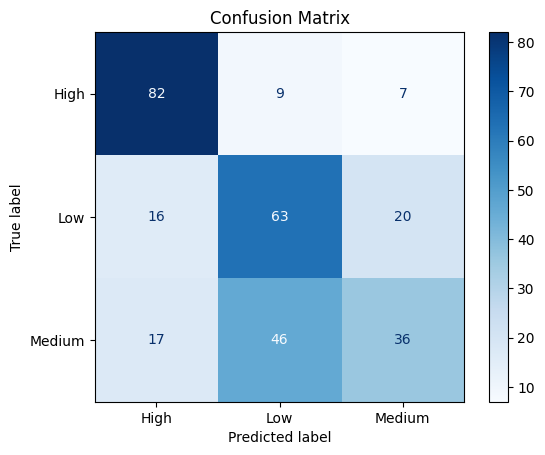

In [21]:
# 5. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_stress.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [22]:
# Cross-validation menggunakan 5-fold pada data resampled
cv_scores = cross_val_score(model, X_resampled, y_resampled, cv=5, scoring='accuracy')
print("\nHasil Cross-Validation (5-Fold):")
print("Skor tiap fold:", np.round(cv_scores, 4))
print("Rata-rata akurasi:", np.round(cv_scores.mean(), 4))
print("Standar deviasi skor:", np.round(cv_scores.std(), 4))


Hasil Cross-Validation (5-Fold):
Skor tiap fold: [0.5236 0.5322 0.6068 0.6881 0.6915]
Rata-rata akurasi: 0.6085
Standar deviasi skor: 0.0725


### Unsupervised Learning

Training & Evaluasi Model Clustering
  <br>Model: KMeans



In [23]:
# Ambil fitur numerik utama untuk clustering (tanpa label)
features_for_clustering = ['Age', 'Screen Time (hrs/day)', 'Sleep Duration (hrs)', 'Physical Activity (hrs/week)']
X_cluster = df[features_for_clustering]

In [24]:
# Scaling fitur
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

In [25]:
# Reduksi dimensi dengan PCA agar bisa divisualisasikan (opsional tapi sangat berguna)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster_scaled)

In [26]:
# Clustering dengan KMeans (misal, cari 3 cluster)
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_cluster_scaled)


In [27]:
# Evaluasi clustering dengan Silhouette Score
sil_score = silhouette_score(X_cluster_scaled, clusters)
print(f"Silhouette Score untuk KMeans (3 cluster): {sil_score:.4f}")

Silhouette Score untuk KMeans (3 cluster): 0.1682


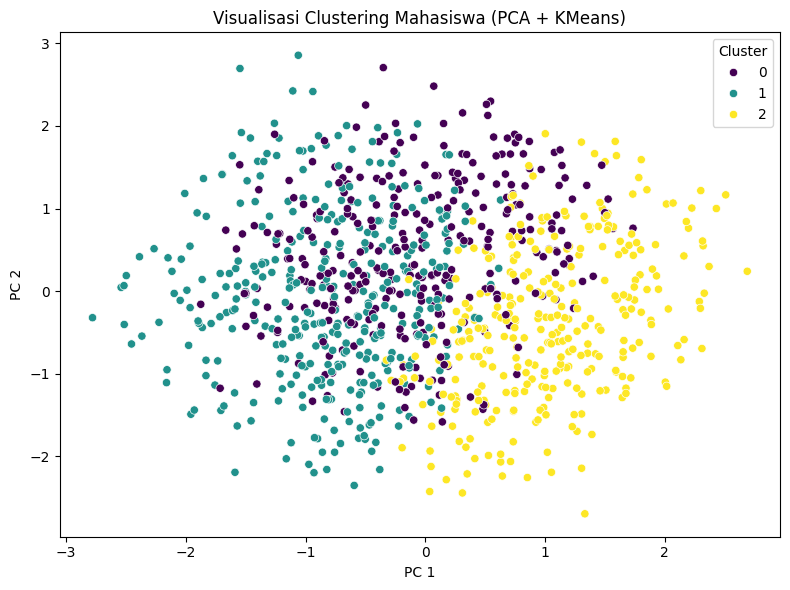

In [28]:
# Visualisasi cluster hasil PCA
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=clusters, palette='viridis')
plt.title("Visualisasi Clustering Mahasiswa (PCA + KMeans)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()


# Jawaban Masalah

1. Bagaimana memprediksi tingkat stres mahasiswa selama pembelajaran daring menggunakan data aktivitas harian mereka?

Model RandomForestClassifier digunakan untuk memprediksi tingkat stres mahasiswa berdasarkan data aktivitas harian seperti screen time, durasi tidur, aktivitas fisik, usia, dan gender.
Hasil evaluasi menunjukkan akurasi sebesar 61.15%, yang dianggap cukup baik mengingat jumlah fitur terbatas dan target klasifikasi terdiri dari tiga kelas (Low, Medium, High).
Ini membuktikan bahwa pola hidup harian dapat digunakan sebagai indikator awal dalam mendeteksi tingkat stres mahasiswa secara otomatis.

2. Fitur apa saja yang paling berpengaruh terhadap tingkat stres?

Model ini menggunakan metode Mutual Information untuk mengukur tingkat ketergantungan antara setiap fitur dengan label Stress Level. Semakin tinggi nilai mutual information, semakin besar pengaruh fitur tersebut terhadap target.

C:\Users\Administrator\AppData\Local\Temp\ipykernel_7624\1314908107.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mutual Information', y='Fitur', data=importance_df, palette='crest')


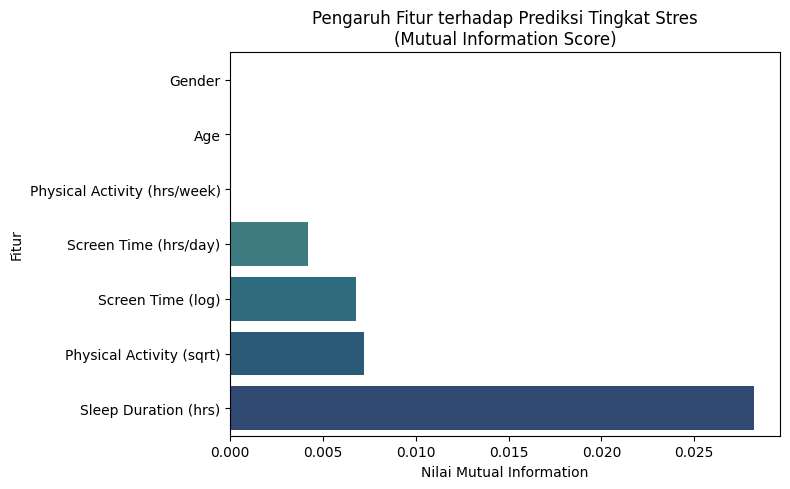

In [29]:
# Hitung mutual information
importances = mutual_info_classif(X, y, discrete_features="auto")

# Buat DataFrame untuk visualisasi
importance_df = pd.DataFrame({
    'Fitur': X.columns,
    'Mutual Information': importances
}).sort_values(by='Mutual Information', ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x='Mutual Information', y='Fitur', data=importance_df, palette='crest')
plt.title("Pengaruh Fitur terhadap Prediksi Tingkat Stres\n(Mutual Information Score)")
plt.xlabel("Nilai Mutual Information")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

Hasil menunjukkan:
Sleep Duration, Screen Time, dan Physical Activity memiliki pengaruh paling tinggi.

Gender memiliki pengaruh paling kecil dalam model ini.

3. Apakah pola hidup mahasiswa dapat dikelompokkan ke dalam tipe-tipe tertentu tanpa melihat tingkat stres secara langsung?

Ya, model ini menggunakan Unsupervised Learning (KMeans Clustering) untuk mengelompokkan mahasiswa berdasarkan fitur numerik:

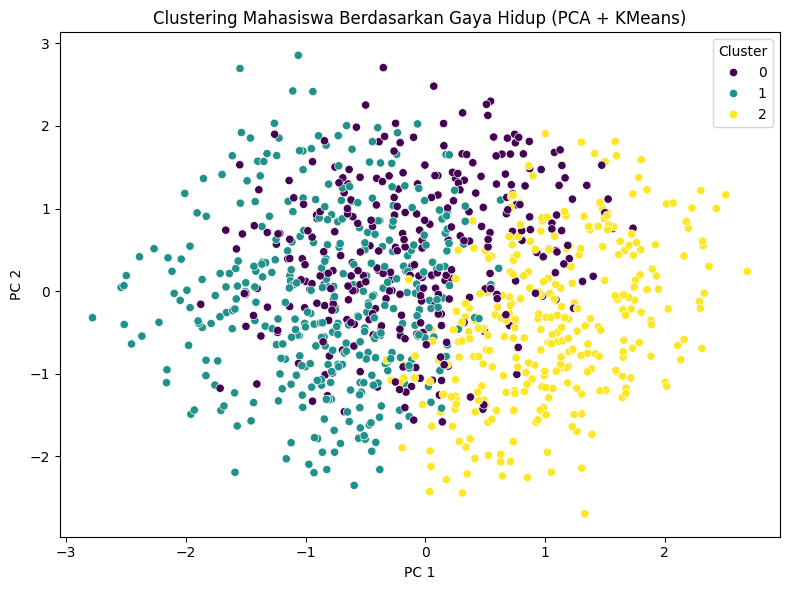

In [30]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=clusters, palette='viridis')
plt.title("Clustering Mahasiswa Berdasarkan Gaya Hidup (PCA + KMeans)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

Model menggunakan PCA untuk reduksi dimensi dan Silhouette Score untuk mengevaluasi kualitas cluster.

4. Seberapa akurat model dalam mengklasifikasikan tingkat stres mahasiswa baru berdasarkan data sederhana?

Model dievaluasi menggunakan data uji setelah dilakukan SMOTE (balancing). Hasil evaluasi:
Akurasi: ~61%

Metode Evaluasi:

accuracy_score

classification_report

confusion_matrix

cross_val_score (5-Fold)

Meskipun hanya menggunakan fitur sederhana, model mampu membuat klasifikasi 3 kelas (Low, Medium, High) dengan cukup baik.

Akurasi: 0.6115
Classification Report:
              precision    recall  f1-score   support

        High       0.71      0.84      0.77        98
         Low       0.53      0.64      0.58        99
      Medium       0.57      0.36      0.44        99

    accuracy                           0.61       296
   macro avg       0.61      0.61      0.60       296
weighted avg       0.61      0.61      0.60       296

Rata-rata cross-validation: 0.6085


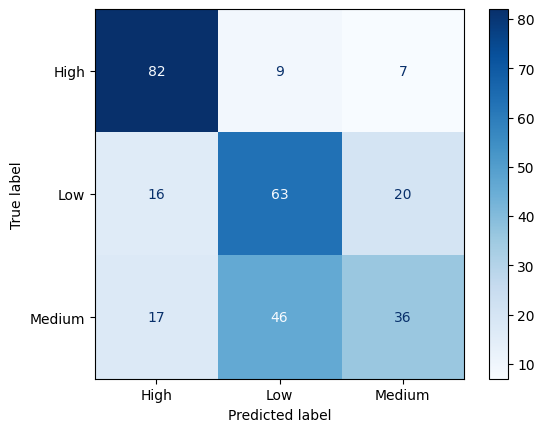

In [31]:
# Akurasi
acc = accuracy_score(y_test, y_pred)
print(f"Akurasi: {acc:.4f}")

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le_stress.classes_))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_stress.classes_).plot(cmap="Blues")

# Cross-validation
cv_scores = cross_val_score(model, X_resampled, y_resampled, cv=5, scoring='accuracy')
print("Rata-rata cross-validation:", np.round(cv_scores.mean(), 4))

# Deployment / Implementasi

In [32]:
import pickle

with open('Tubes_Damin.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model berhasil diekspor ke Tubes_Damin.pkl")

Model berhasil diekspor ke Tubes_Damin.pkl


In [33]:
with open('Tubes_Damin.pkl', 'rb') as file:
    model = pickle.load(file)

print("Model berhasil dimuat kembali.")

Model berhasil dimuat kembali.


In [34]:
# Simpan scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Simpan LabelEncoder untuk Gender
with open('label_encoder_gender.pkl', 'wb') as f:
    pickle.dump(le_gender, f)

# Simpan LabelEncoder untuk Stress Level
with open('label_encoder_stress.pkl', 'wb') as f:
    pickle.dump(le_stress, f)


In [35]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
pip install pyngrok

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
!ngrok config add-authtoken 2ynjAWrNd4G016yV43YZYryBAkJ_3d99XqEundo7YtxzotzrR

Authtoken saved to configuration file: C:\Users\Administrator\AppData\Local/ngrok/ngrok.yml


In [38]:
import os

os.system("ngrok config add-authtoken 2ynjAWrNd4G016yV43YZYryBAkJ_3d99XqEundo7YtxzotzrR")

0

In [41]:
%%writefile app.py
# =======================================
#  IMPORT LIBRARY
# =======================================
import pandas as pd
import numpy as np
import pickle
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE

# =======================================
#  LOAD MODEL DAN OBJEK PENDUKUNG
# =======================================
pickle_in = open('Tubes_Damin.pkl', 'rb')
model = pickle.load(pickle_in)
scaler = pickle.load(open('scaler.pkl', 'rb'))
le_stress = pickle.load(open('label_encoder_stress.pkl', 'rb'))
le_gender = pickle.load(open('label_encoder_gender.pkl', 'rb'))

# =======================================
#  FUNGSI PREDIKSI STRES
# =======================================
def predict_stress(gender, age, screen_time, sleep_duration, physical_activity):
    df_input = pd.DataFrame({
        'Gender': [le_gender.transform([gender])[0]],
        'Age': [age],
        'Screen Time (hrs/day)': [screen_time],
        'Sleep Duration (hrs)': [sleep_duration],
        'Physical Activity (hrs/week)': [physical_activity],
        'Screen Time (log)': [np.log1p(screen_time)],
        'Physical Activity (sqrt)': [np.sqrt(physical_activity)]
    })

    X_scaled = scaler.transform(df_input)
    pred = model.predict(X_scaled)
    pred_label = le_stress.inverse_transform(pred)[0]
    return pred_label

# =======================================
#  APLIKASI STREAMLIT UTAMA
# =======================================
def main():
    st.set_page_config(page_title="Student Stress Predictor", layout="centered")
    st.title("Student Stress Level Classification App")

    st.markdown("""
    <div style='background-color:#2C6E91; padding:10px; border-radius:10px'>
    <h3 style='color:white; text-align:center'>Cek Tingkat Stres Anda Selama Pembelajaran Online</h3>
    </div>
    """, unsafe_allow_html=True)

    st.header("Input Data Mahasiswa")
    gender = st.selectbox("Gender", ["Male", "Female", "Other"])
    age = st.slider("Usia", 15, 25, 20)
    screen_time = st.slider("Durasi Screen Time (jam/hari)", 1.0, 12.0, 6.0)
    sleep_duration = st.slider("Durasi Tidur (jam)", 3.0, 10.0, 6.5)
    physical_activity = st.slider("Aktivitas Fisik (jam/minggu)", 0.0, 10.0, 3.0)

    if st.button("Prediksi Tingkat Stres"):
        result = predict_stress(gender, age, screen_time, sleep_duration, physical_activity)
        st.success(f"Prediksi Tingkat Stres Anda: {result}")

    st.markdown("---")
    st.header("Akurasi Model")

    # Hitung akurasi berdasarkan test set statis (opsional bisa diubah)
    df = pd.read_csv("Student Mental Health Analysis.csv")
    df.drop(columns=['Name'], inplace=True)
    df['Gender'] = df['Gender'].str.strip().str.capitalize()
    df['Stress Level'] = df['Stress Level'].str.strip().str.capitalize()
    df['Gender'] = le_gender.transform(df['Gender'])
    df['Stress Level'] = le_stress.transform(df['Stress Level'])
    df['Screen Time (log)'] = np.log1p(df['Screen Time (hrs/day)'])
    df['Physical Activity (sqrt)'] = np.sqrt(df['Physical Activity (hrs/week)'])

    X = df.drop("Stress Level", axis=1)
    y = df["Stress Level"]
    X_scaled = scaler.transform(X)
    smote = SMOTE(random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_scaled, y)
    X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled)

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    st.metric(label="Akurasi Random Forest", value=f"{acc*100:.2f}%")

    st.caption("Model menggunakan RandomForestClassifier dengan preprocessing StandardScaler, LabelEncoder, dan SMOTE untuk balancing.")

#  Eksekusi utama
if __name__ == '__main__':
    main()


Overwriting app.py


In [40]:
from pyngrok import ngrok
import threading
import os

ngrok.kill()

def run_streamlit():
    os.system("streamlit run app.py --server.port 8501")

# Jalankan Streamlit di thread terpisah
thread = threading.Thread(target=run_streamlit)
thread.start()

# Ekspos Streamlit ke internet menggunakan Ngrok
public_url = ngrok.connect(addr="8501")
print(f"Streamlit app is live at: {public_url}")

Streamlit app is live at: NgrokTunnel: "https://d057-202-46-68-163.ngrok-free.app" -> "http://localhost:8501"


t=2025-06-22T22:55:59+0700 lvl=warn msg="failed to open private leg" id=0cee37c5b476 privaddr=localhost:8501 err="dial tcp [::1]:8501: connectex: No connection could be made because the target machine actively refused it."
t=2025-06-22T22:56:00+0700 lvl=warn msg="failed to open private leg" id=f12ec7ddc63e privaddr=localhost:8501 err="dial tcp [::1]:8501: connectex: No connection could be made because the target machine actively refused it."
t=2025-06-22T22:56:26+0700 lvl=eror msg="session closed, starting reconnect loop" obj=tunnels.session obj=csess id=b5e2fe67963c err="read tcp 192.168.1.6:53314->3.136.132.147:443: wsarecv: An established connection was aborted by the software in your host machine."
t=2025-06-22T22:56:29+0700 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: Your account is limited to 1 simultaneous ngrok agent sessions.\nYou can run multiple simultaneous tunnels from a single agent session by defining the tunnels in your age